In [3]:
import os
import zipfile

# Ensure kaggle CLI is installed
!pip install -q kaggle

# --- Instructions ---
# Please upload your 'kaggle.json' file to /content/ (or your current directory)
# or copy it to '~/.kaggle/kaggle.json' before running this cell.

# Set up directory for Kaggle credentials
kaggle_dir = os.path.expanduser('~/.kaggle')
os.makedirs(kaggle_dir, exist_ok=True)

# If kaggle.json is uploaded in current workspace, move it to the correct folder
if os.path.exists('kaggle.json'):
    os.rename('kaggle.json', os.path.join(kaggle_dir, 'kaggle.json'))
    os.chmod(os.path.join(kaggle_dir, 'kaggle.json'), 0o600)

# Configuration
KAGGLE_DATASET = 'kyanyoga/sample-sales-data'
TARGET_NAME = 'sales_data_sample.csv'

# Download dataset zip using official Kaggle API
!kaggle datasets download -d {KAGGLE_DATASET}

# Extract zip and rename/move the csv file
zip_filename = KAGGLE_DATASET.split('/')[-1] + '.zip'
if os.path.exists(zip_filename):
    with zipfile.ZipFile(zip_filename, 'r') as zip_ref:
        zip_ref.extractall('temp_extracted')

    # Find the csv and place it at root
    for root, dirs, files in os.walk('temp_extracted'):
        for file in files:
            if file.endswith('.csv'):
                os.rename(os.path.join(root, file), TARGET_NAME)
                print(f'Successfully saved dataset as {TARGET_NAME}')
                break

    # Clean up temporary files
    os.remove(zip_filename)
    import shutil
    shutil.rmtree('temp_extracted')
else:
    print("Ensure you have uploaded kaggle.json so the API can download the dataset.")

Dataset URL: https://www.kaggle.com/datasets/kyanyoga/sample-sales-data
License(s): CC0-1.0
100% 77.5k/77.5k [00:00<00:00, 388kB/s]

Successfully saved dataset as sales_data_sample.csv


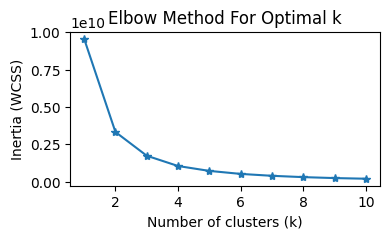

ValueError: 0       2
1       2
2       2
3       2
4       3
       ..
2818    0
2819    2
2820    3
2821    0
2822    2
Name: Cluster, Length: 2823, dtype: int32 is not a valid value for color: supported inputs are (r, g, b) and (r, g, b, a) 0-1 float tuples; '#rrggbb', '#rrggbbaa', '#rgb', '#rgba' strings; named color strings; string reprs of 0-1 floats for grayscale values; 'C0', 'C1', ... strings for colors of the color cycle; and pairs combining one of the above with an alpha value

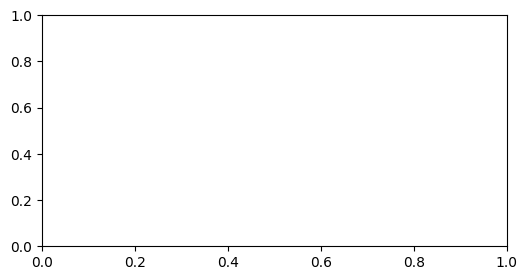

In [25]:
# Clustering on Sales Data (K-Means & Elbow Method)
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# 1. Load the dataset (Upload 'sales_data_sample.csv' to Colab first)
# Note: This file is often encoded in 'latin-1' instead of default 'utf-8'
df = pd.read_csv('sales_data_sample.csv', encoding='latin-1')

# 2. Pre-process data
# We will cluster based on the 'SALES' column. Drop missing values to be safe.
sales_data = df[['SALES']].dropna()

# 3. Determine number of clusters using the Elbow Method
inertia = []
K_range = range(1, 11) # Testing 1 to 10 clusters

for k in K_range:
    kmeans = KMeans(n_clusters=k, n_init=10)
    kmeans.fit(sales_data)
    inertia.append(kmeans.inertia_) # Inertia = sum of squared distances to closest cluster center

# Plot the Elbow Curve
plt.figure(figsize=(4, 2))
plt.plot(K_range, inertia, marker='*')
plt.title('Elbow Method For Optimal k')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia (WCSS)')
plt.show()

# 4. Implement K-Means with the chosen number of clusters
# Looking at the plot, the "elbow" usually bends around k=3 or k=4.
optimal_k = 4
kmeans_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
kmeans_final.fit(sales_data)
df['Cluster'] = kmeans_final.predict(sales_data)

# 5. Visualize the clusters (Scatter plot of Order Number vs Sales)
plt.figure(figsize=(6, 3))
plt.scatter(df.index, df['SALES'], c=df['Cluster'])
plt.title(f'K-Means Clusters (k={optimal_k})')
plt.xlabel('Data Point Index')
plt.ylabel('Sales Amount')
plt.show()

# (Optional) Print cluster centers
print("Cluster Centers (Sales Amounts):")
print(kmeans_final.cluster_centers_)